In [1]:
import os

def show_inputs(depth=4, max_files_per_dir=6):
    """Print what is attached under /kaggle/input - check it before trusting the rest."""
    root0 = os.environ.get("SAT_INPUT", "/kaggle/input")
    for root, dirs, files in os.walk(root0):
        dirs[:] = sorted(d for d in dirs if not d.startswith("."))
        level = root.replace(root0, "").count(os.sep)
        if level > depth:
            dirs[:] = []
            continue
        print("  " * level + root + "/")
        for fn in sorted(files)[:max_files_per_dir]:
            print("  " * level + "  " + fn)
        if len(files) > max_files_per_dir:
            print("  " * level + f"  ... +{len(files) - max_files_per_dir} more files")

show_inputs()

/kaggle/input/
  /kaggle/input/datasets/
    /kaggle/input/datasets/rollsroyce1/
      /kaggle/input/datasets/rollsroyce1/sat-ext/
        /kaggle/input/datasets/rollsroyce1/sat-ext/sat_ext/
          README.md
          analysis.py
          audit.py
          config.py
          dataset.py
          dota.py
          ... +10 more files
      /kaggle/input/datasets/rollsroyce1/sat-results-03/
        /kaggle/input/datasets/rollsroyce1/sat-results-03/results/
      /kaggle/input/datasets/rollsroyce1/sat-results-07a/
        yolo11s.pt
        yolo26n.pt
        /kaggle/input/datasets/rollsroyce1/sat-results-07a/results/
        /kaggle/input/datasets/rollsroyce1/sat-results-07a/results_07A/
        /kaggle/input/datasets/rollsroyce1/sat-results-07a/weights/
          grouped__YOLO11s-1024__s42_best.pt
          grouped__YOLO11s-1024__s43_best.pt
          grouped__YOLO11s-1024__s44_best.pt
          grouped__YOLO11s-1280__s42_best.pt
          grouped__YOLO11s-1280__s43_best.pt
       

In [2]:
import os, sys, warnings
warnings.filterwarnings("ignore")
INPUT_ROOT = os.environ.get("SAT_INPUT", "/kaggle/input")

def _find_code_root():
    for root, dirs, files in os.walk(INPUT_ROOT):
        if {"config.py", "audit.py", "metrics.py", "infer.py"} <= set(files):
            return root
    return None

CODE_ROOT = os.environ.get("SAT_CODE") or _find_code_root()
assert CODE_ROOT, "sat_ext code folder not found - Add Input -> your 'sat-ext' code Dataset"
sys.path.insert(0, CODE_ROOT)
print("CODE_ROOT:", CODE_ROOT)

import numpy as np, pandas as pd
pd.set_option("display.width", 250); pd.set_option("display.max_columns", 60); pd.set_option("display.max_colwidth", 70)
import config as cfg, utils
utils.ensure_dirs(); utils.set_seed(cfg.SEED)
print("work dir:", cfg.WORK_DIR, "| smoke test:", cfg.SMOKE)

CODE_ROOT: /kaggle/input/datasets/rollsroyce1/sat-ext/sat_ext
work dir: /kaggle/working | smoke test: False


In [3]:
utils.warn_if_gpu_wasted()
import report, plans, dataset as ds
runs = report.collect_runs()
df = report.long_table(runs)
os.makedirs(report.PAPER_DIR, exist_ok=True)
df.drop(columns=["folder"]).to_csv(os.path.join(report.PAPER_DIR, "all_runs_long.csv"), index=False)
expected = set(plans.expected_run_ids())
optional = set(plans.expected_run_ids(include_optional=True)) - expected
print("phase-2 / optional runs found:", len(optional & set(runs)), "of", len(optional),
      "| not found:", sorted(optional - set(runs))[:40])
missing = sorted(expected - set(runs))
print("expected runs:", len(expected), "| found:", len(expected & set(runs)), "| MISSING:", missing or "none")
print("extra runs (legacy etc.):", sorted(set(runs) - expected))
for rid, (d, _) in runs.items():
    if "engine_check" in d:
        print("pycocotools vs internal AP (should be equal):", rid, d["engine_check"])

126 evaluated runs found (+52 TTA / inference-resolution modes from 08D)
phase-2 / optional runs found: 86 of 86 | not found: []
expected runs: 20 | found: 20 | MISSING: none
extra runs (legacy etc.): ['grouped_1copy__YOLO11m__s42', 'grouped_1copy__YOLO11m__s43', 'grouped_1copy__YOLO11m__s44', 'grouped_1copy__YOLO11s__s42', 'grouped_1copy__YOLO11s__s43', 'grouped_1copy__YOLO11s__s44', 'grouped__YOLO11m-1024__s42', 'grouped__YOLO11m-1024__s43', 'grouped__YOLO11m-1024__s44', 'grouped__YOLO11m-1280__s42', 'grouped__YOLO11m-1280__s43', 'grouped__YOLO11m-1280__s44', 'grouped__YOLO11s-1024__s42', 'grouped__YOLO11s-1024__s43', 'grouped__YOLO11s-1024__s44', 'grouped__YOLO11s-1280__s42', 'grouped__YOLO11s-1280__s43', 'grouped__YOLO11s-1280__s44', 'grouped__YOLO12m__s42', 'grouped__YOLO12m__s43', 'grouped__YOLO12m__s44', 'grouped__YOLO12s__s42', 'grouped__YOLO12s__s43', 'grouped__YOLO12s__s44', 'grouped__YOLO26m__s42', 'grouped__YOLO26m__s43', 'grouped__YOLO26m__s44', 'grouped__YOLO26s__s42', 'g

In [4]:
t1 = report.table_main(df, "grouped")
t2 = report.table_sahi(df, "grouped")
t3 = report.table_bootstrap(df, "grouped")
t4 = report.table_per_class(df, "grouped")
t5 = report.table_orig_vs_grouped(df)
if (df.split == "orig").any():
    report.table_sahi(df, "orig")
if (df.split == "sky_grouped").any():           # second dataset (one seed)
    report.table_main(df, "sky_grouped"); report.table_sahi(df, "sky_grouped"); report.table_per_class(df, "sky_grouped")
    report.fig_pareto(df, "sky_grouped"); report.fig_size_recall(df, "sky_grouped")
t6 = report.table_transfer(df)
report.table_splits_compare(df, ["grouped_1copy", "grouped"], ["YOLO11s", "YOLO11m"], "T7a_offline_augmentation",
    "Offline augmentation ablation: train on 1 vs all 3 Roboflow augmented copies per source (same test images).")
report.table_splits_compare(df, [f"grouped_lc{int(f * 100)}" for f in cfg.LEARNING_CURVE] + ["grouped"], ["YOLO11s", "YOLO11m"],
    "T7b_learning_curve", "Learning curve: share of the training ground-area groups used (same test images).")
print(report.fig_learning_curve(df))
report.table_native(df)
abl = report.collect_ablation()
if len(abl):
    report.table_sahi_ablation(abl, "grouped"); report.table_sahi_ablation(abl, "sky_grouped")
report.table_external(df)
report.table_efficiency(df, "grouped")


### T1_main_standard_grouped: Test-set results (grouped split, standard (unsliced) inference at each model's input size, mean $\pm$ std over seeds; GFLOPs at that input size). mAP/P/R from Ultralytics at conf 0.001; AP\_small = COCO AP for area $<32^2$ px$^2$; AR50\_micro = recall at IoU 0.5 for area $<16^2$ px$^2$; latency = end-to-end per image on a T4.
       Model Group  Input  Seeds Params_M GFLOPs             mAP50          mAP50_95                 P                 R          AP_small        AR50_micro          ms_img            FPS
     YOLO11n paper    640      3     2.59     -- 0.722 $\pm$ 0.010 0.395 $\pm$ 0.009 0.784 $\pm$ 0.009 0.625 $\pm$ 0.004 0.278 $\pm$ 0.001 0.469 $\pm$ 0.017  13.4 $\pm$ 0.2 74.6 $\pm$ 1.1
     YOLO11s paper    640      3     9.43     -- 0.749 $\pm$ 0.027 0.420 $\pm$ 0.025 0.787 $\pm$ 0.033 0.670 $\pm$ 0.028 0.308 $\pm$ 0.029 0.494 $\pm$ 0.062  14.1 $\pm$ 0.2 71.2 $\pm$ 1.0
     YOLO11m paper    640      3    20.06     -- 0.676 $\pm$ 0.035 0.318 $\pm

,Model,Train_size,Inference,Seeds,AP,AP_small,AR50_micro,Params_M,GFLOPs_img,ms_img
28,RT-DETR-L,640,Standard,3,0.338 $\pm$ 0.026,0.281 $\pm$ 0.020,0.493 $\pm$ 0.013,32.8,None,59.2 $\pm$ 1.5
27,RT-DETR-L,640,SAHI-480,3,0.337 $\pm$ 0.035,0.300 $\pm$ 0.029,0.573 $\pm$ 0.024,32.8,None,323.7 $\pm$ 10.9
26,RT-DETR-L,640,SAHI-320,3,0.293 $\pm$ 0.029,0.261 $\pm$ 0.016,0.580 $\pm$ 0.024,32.8,None,627.1 $\pm$ 23.2
25,RT-DETR-L,640,SAHI-160,3,0.259 $\pm$ 0.033,0.188 $\pm$ 0.025,0.584 $\pm$ 0.069,32.8,None,1613.4 $\pm$ 76.9
24,RT-DETR-L,640,Inference @1024,2,0.105 $\pm$ 0.035,0.116 $\pm$ 0.031,0.257 $\pm$ 0.094,32.8,None,107.7 $\pm$ 0.7
...,...,...,...,...,...,...,...,...,...,...
50,YOLOv9m,640,SAHI-320,3,0.244 $\pm$ 0.013,0.268 $\pm$ 0.019,0.593 $\pm$ 0.087,20.2,None,331.3 $\pm$ 5.5
36,YOLOv9s,640,Standard,3,0.358 $\pm$ 0.034,0.280 $\pm$ 0.011,0.456 $\pm$ 0.028,7.3,None,20.8 $\pm$ 0.5
35,YOLOv9s,640,SAHI-480,3,0.313 $\pm$ 0.041,0.264 $\pm$ 0.016,0.501 $\pm$ 0.029,7.3,None,121.5 $\pm$ 7.3
34,YOLOv9s,640,SAHI-320,3,0.309 $\pm$ 0.045,0.259 $\pm$ 0.032,0.531 $\pm$ 0.053,7.3,None,213.0 $\pm$ 6.1


In [5]:
for f in [report.fig_pareto(df, "grouped"), report.fig_size_recall(df, "grouped"), report.fig_extra_dets(df, "grouped")]:
    print(f)
info = ds.materialize("grouped")
print(report.fig_qualitative(df, info, split="grouped"))

/kaggle/working/results/paper/fig_pareto_grouped.png
/kaggle/working/results/paper/fig_size_recall_grouped.png
/kaggle/working/results/paper/fig_extra_detections_grouped.png
materialized 'grouped' (f7cee44b1365) -> /kaggle/working/data_grouped  images {'train': 984, 'val': 80, 'test': 82}
/kaggle/working/results/paper/fig_qualitative_grouped.png


fig_extra_detections_grouped.png


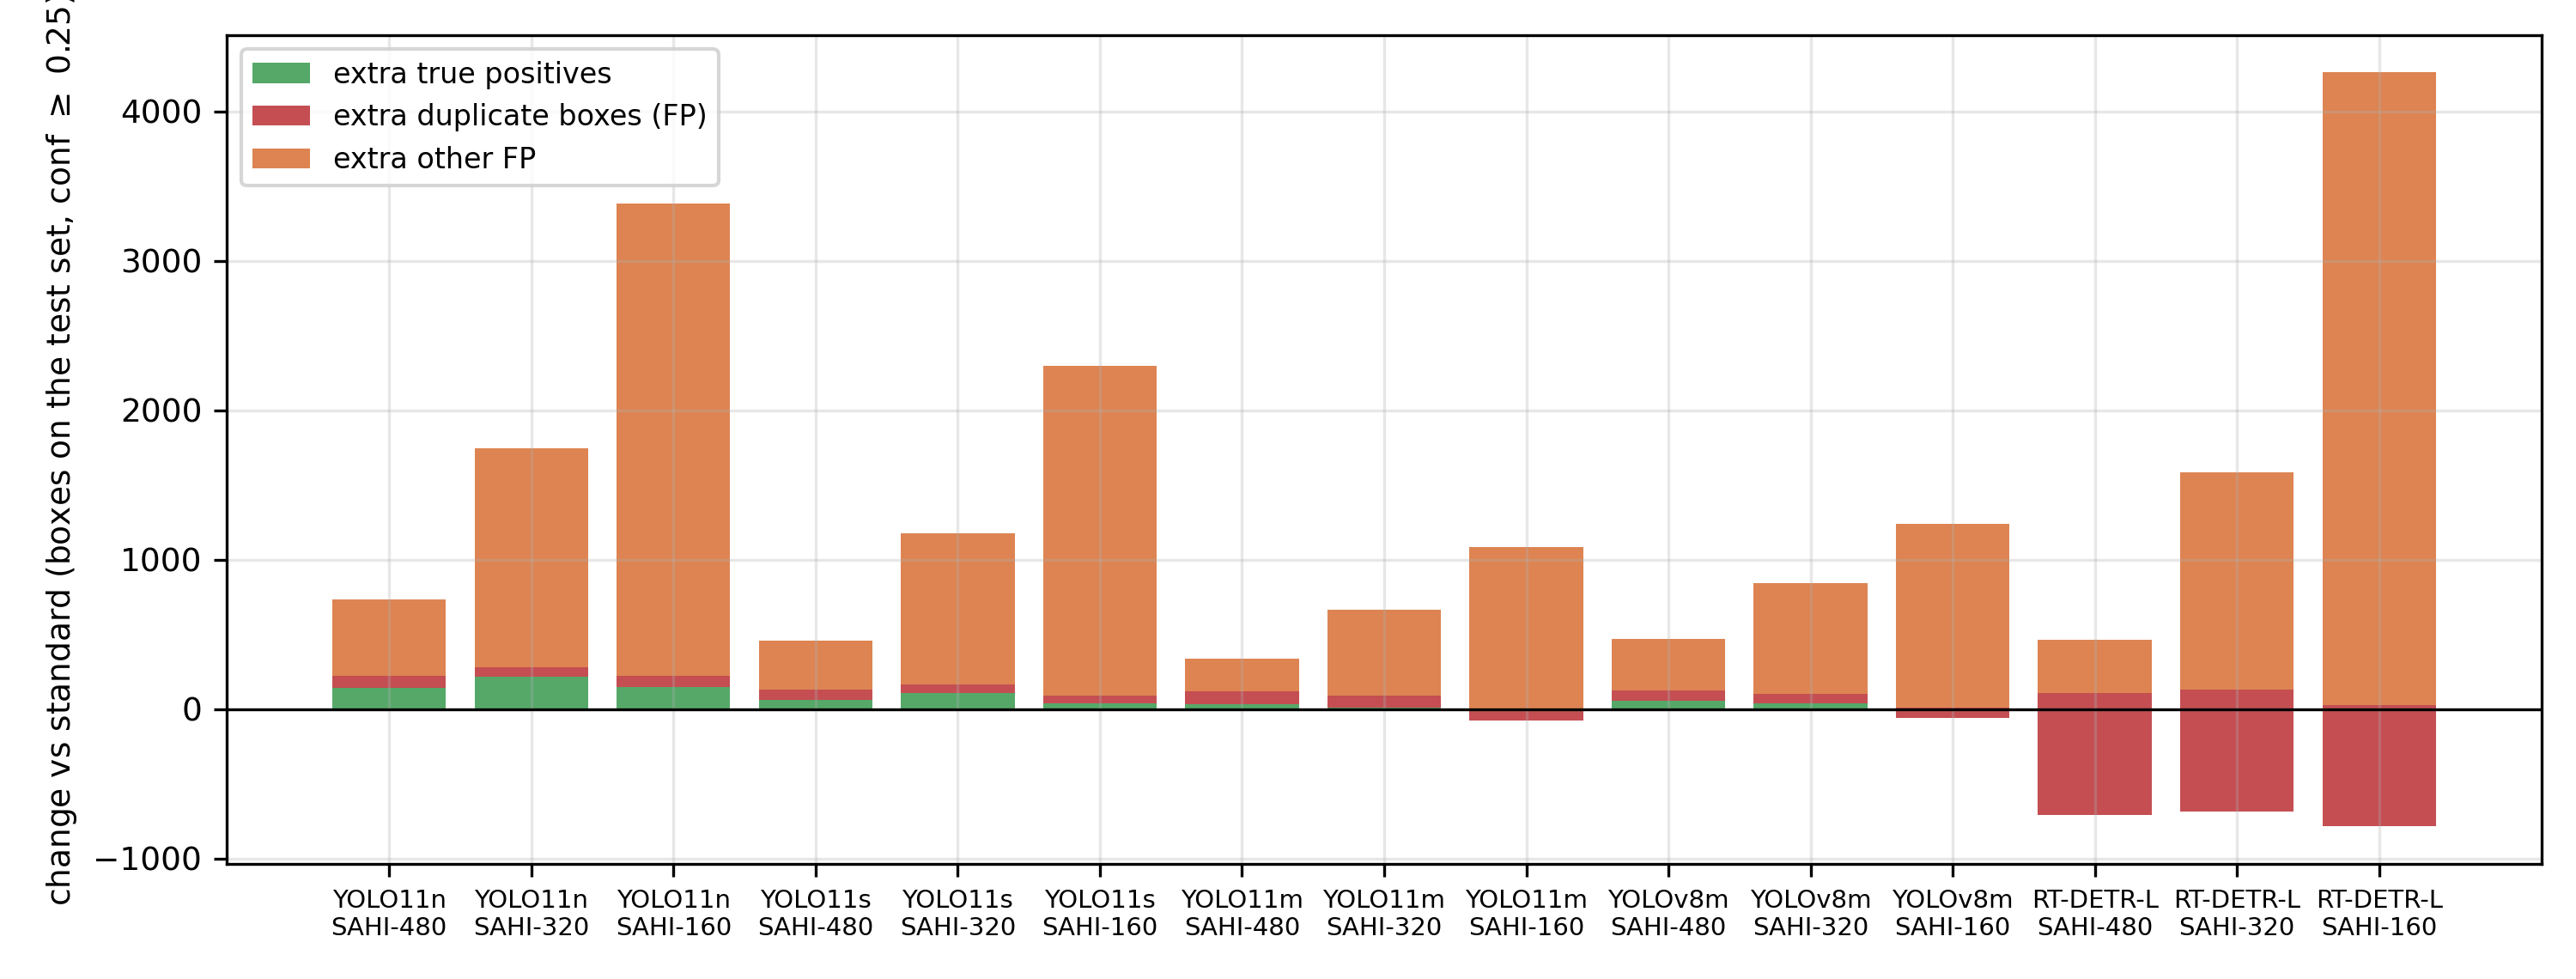

fig_learning_curve.png


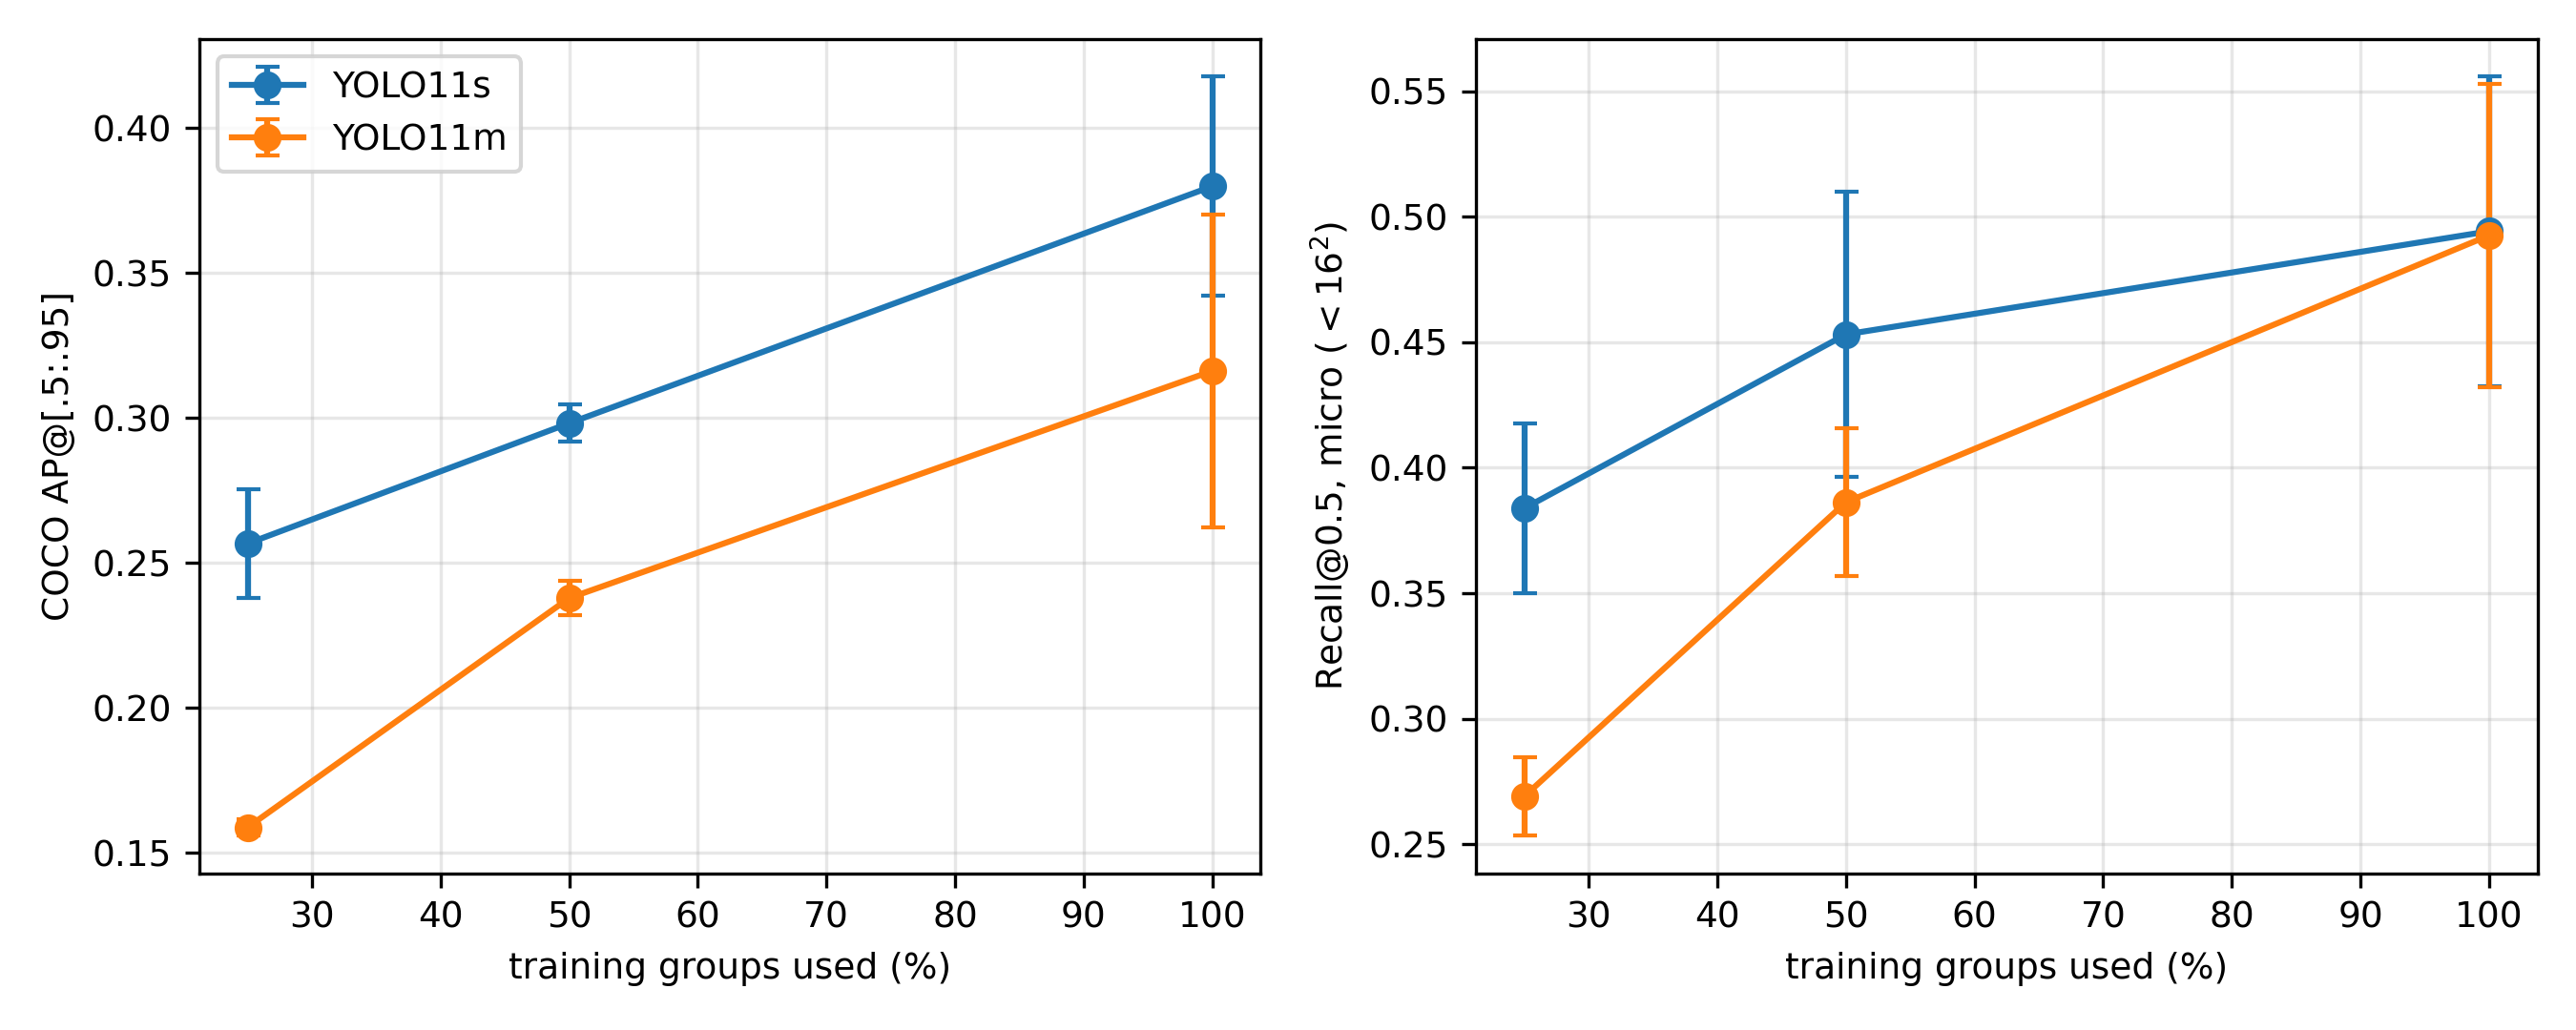

fig_pareto_grouped.png


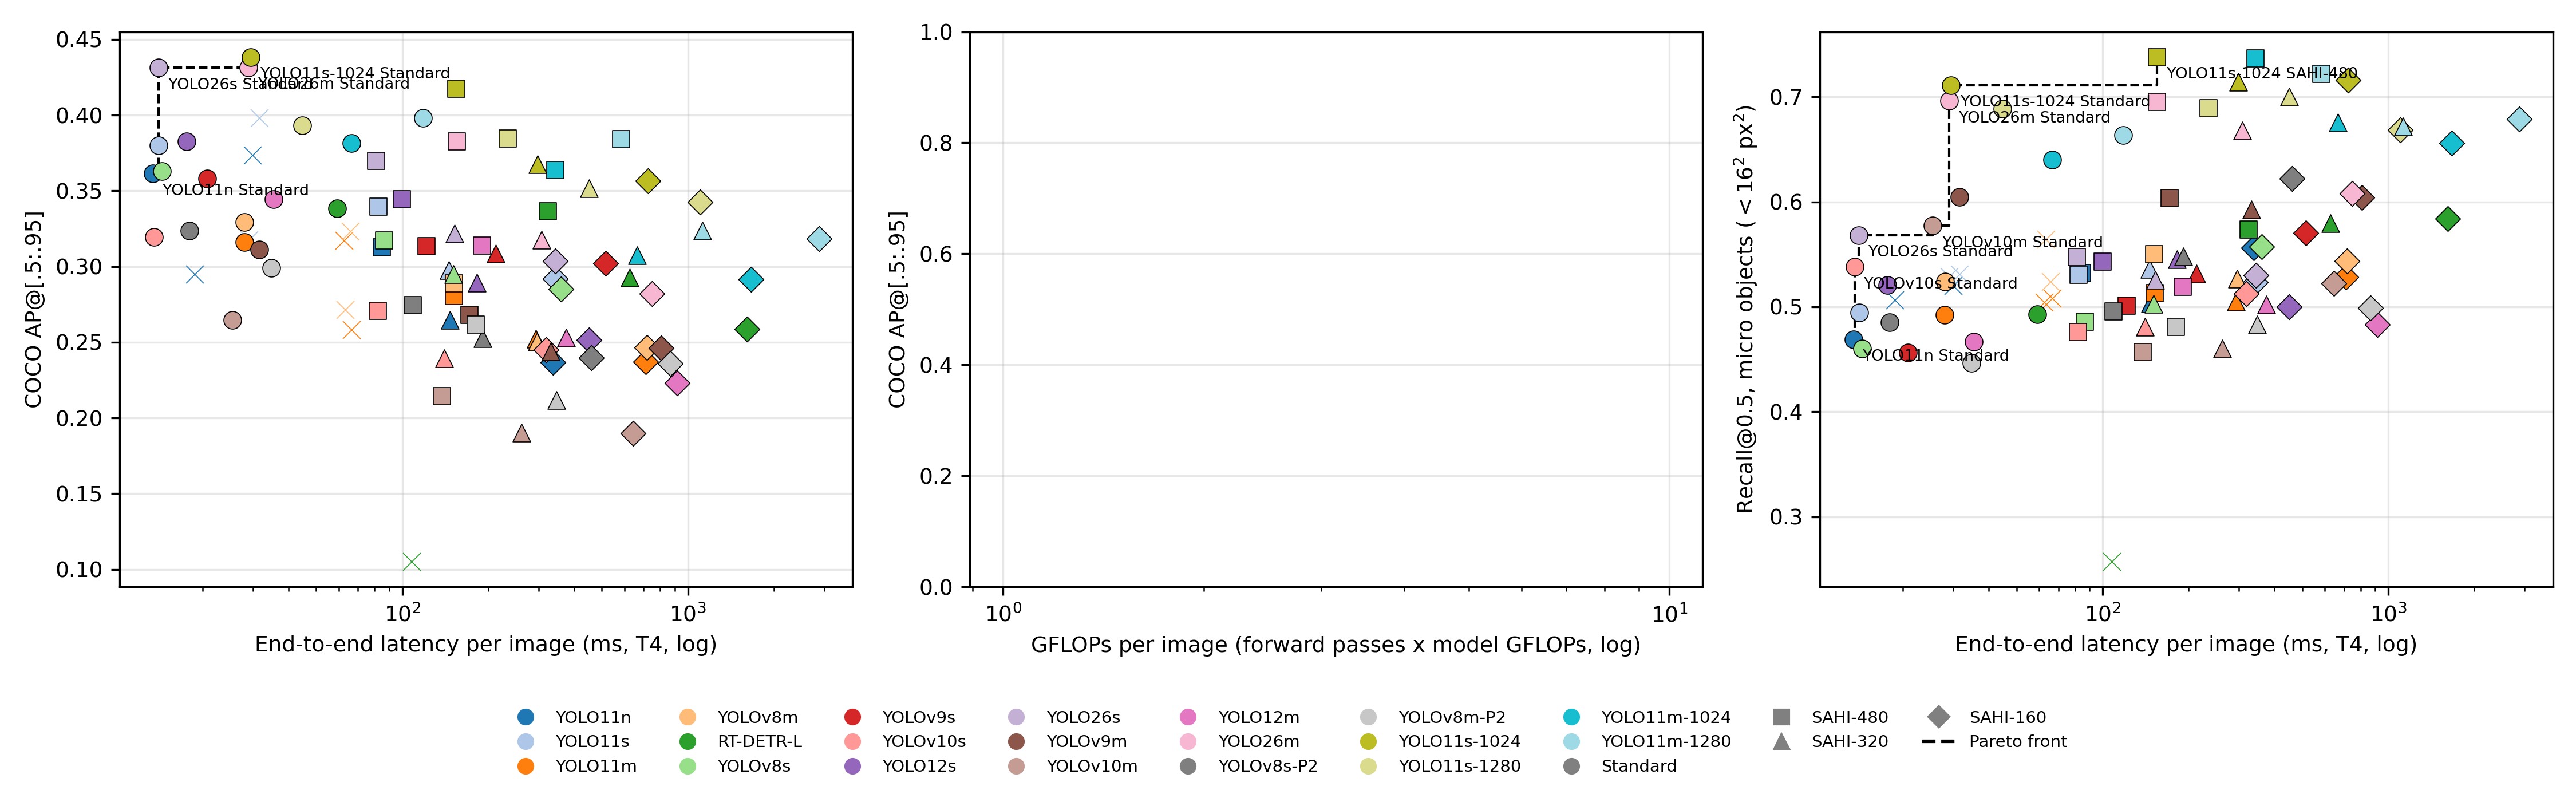

fig_pareto_sky_grouped.png


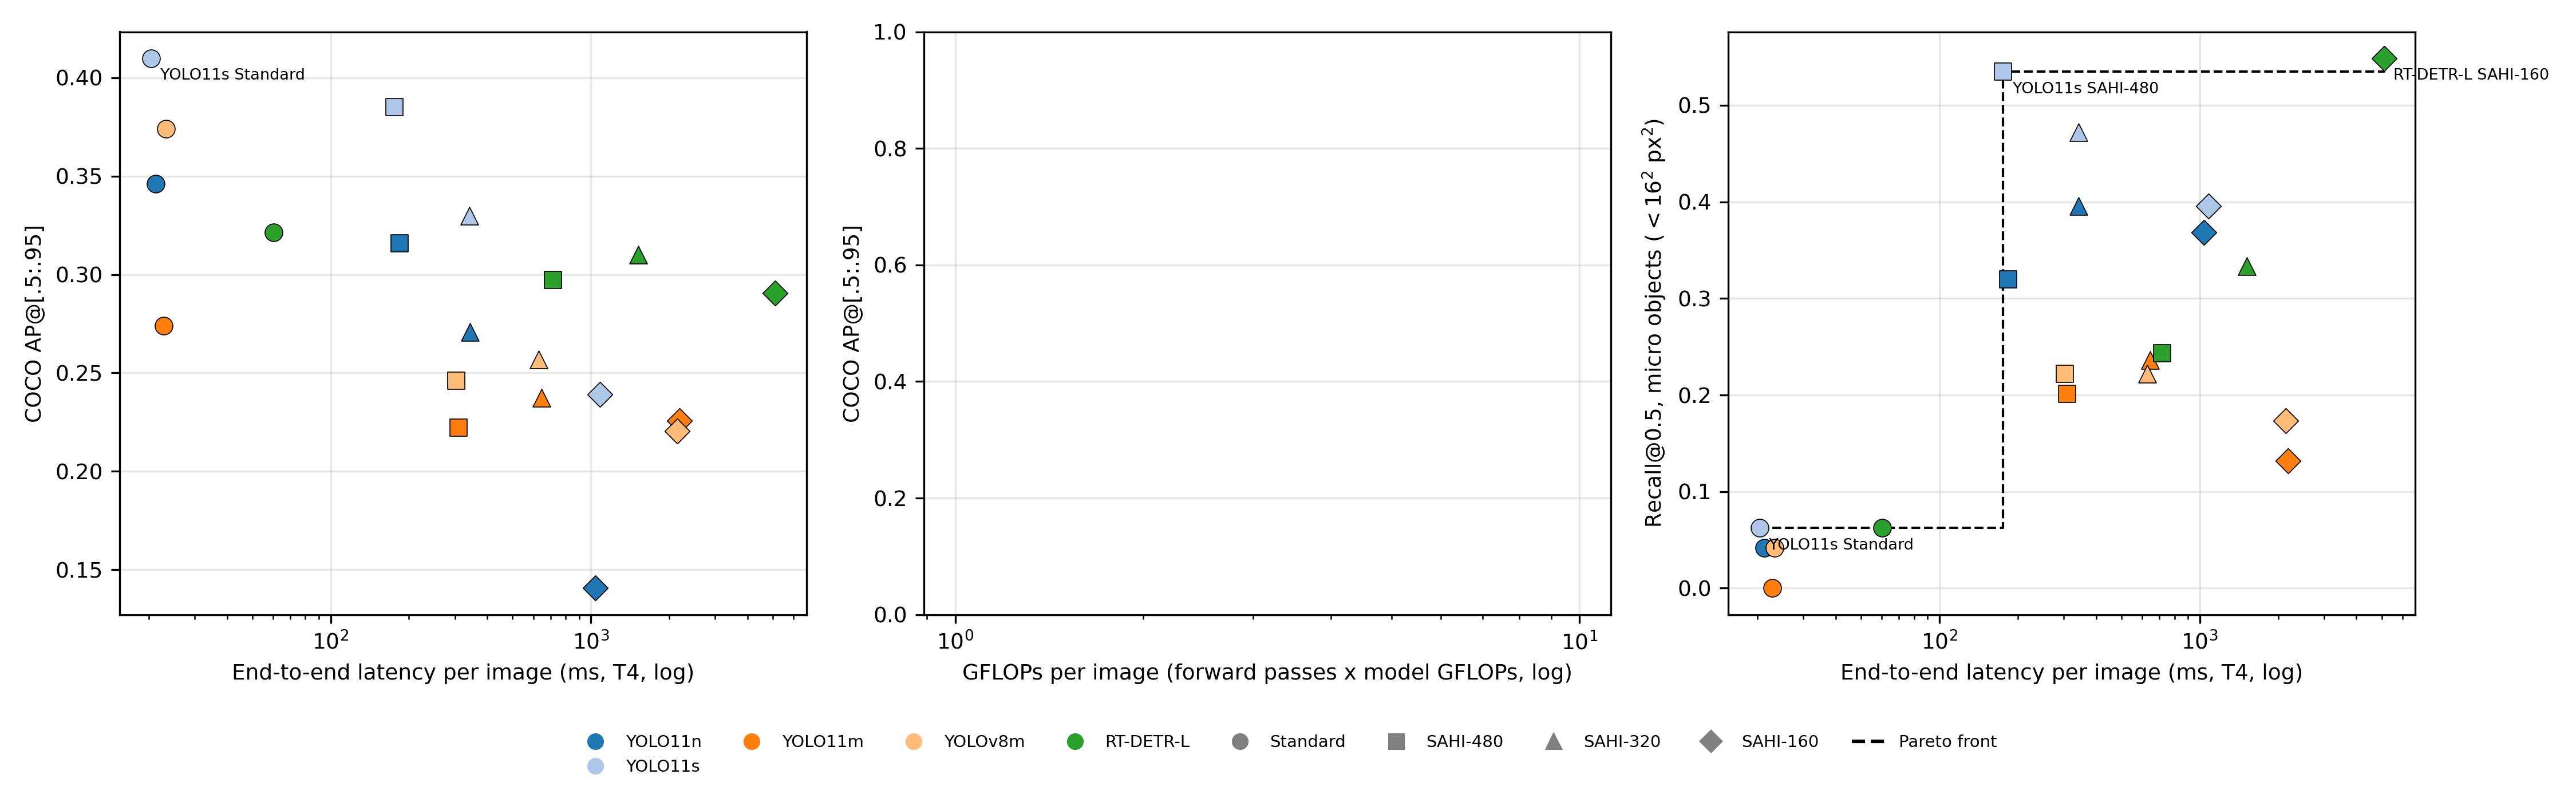

fig_qualitative_grouped.png


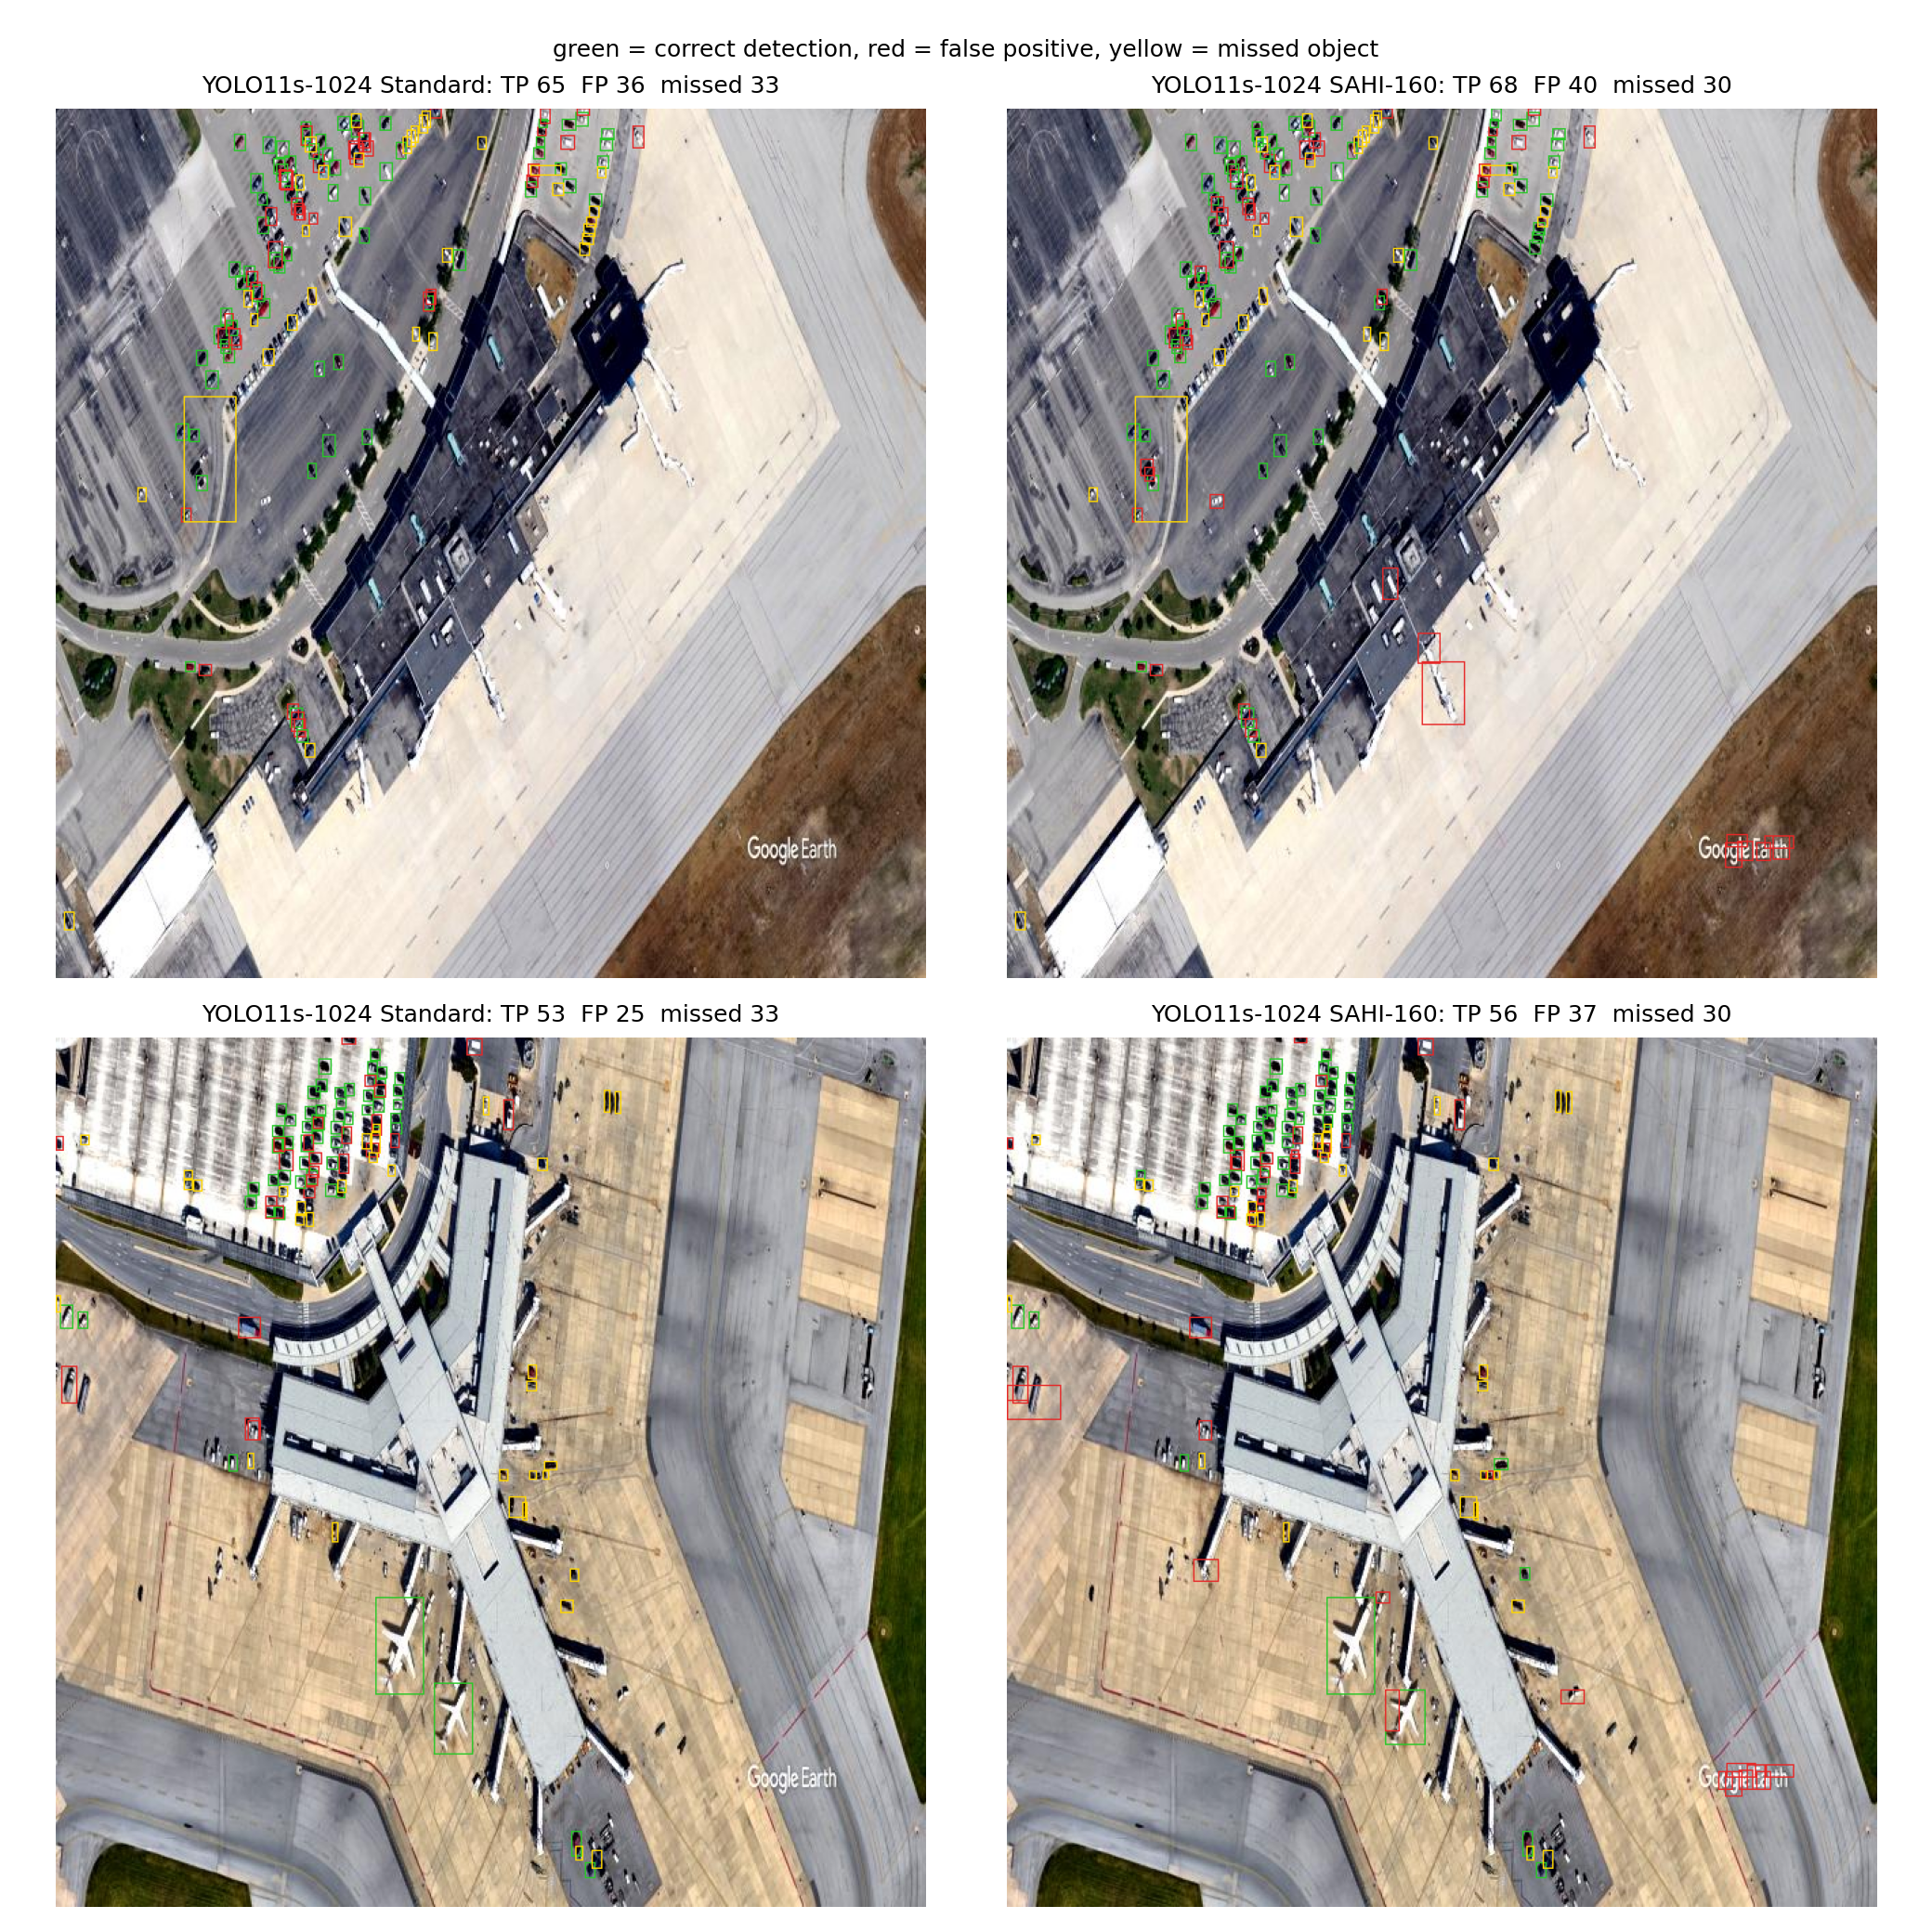

fig_size_recall_grouped.png


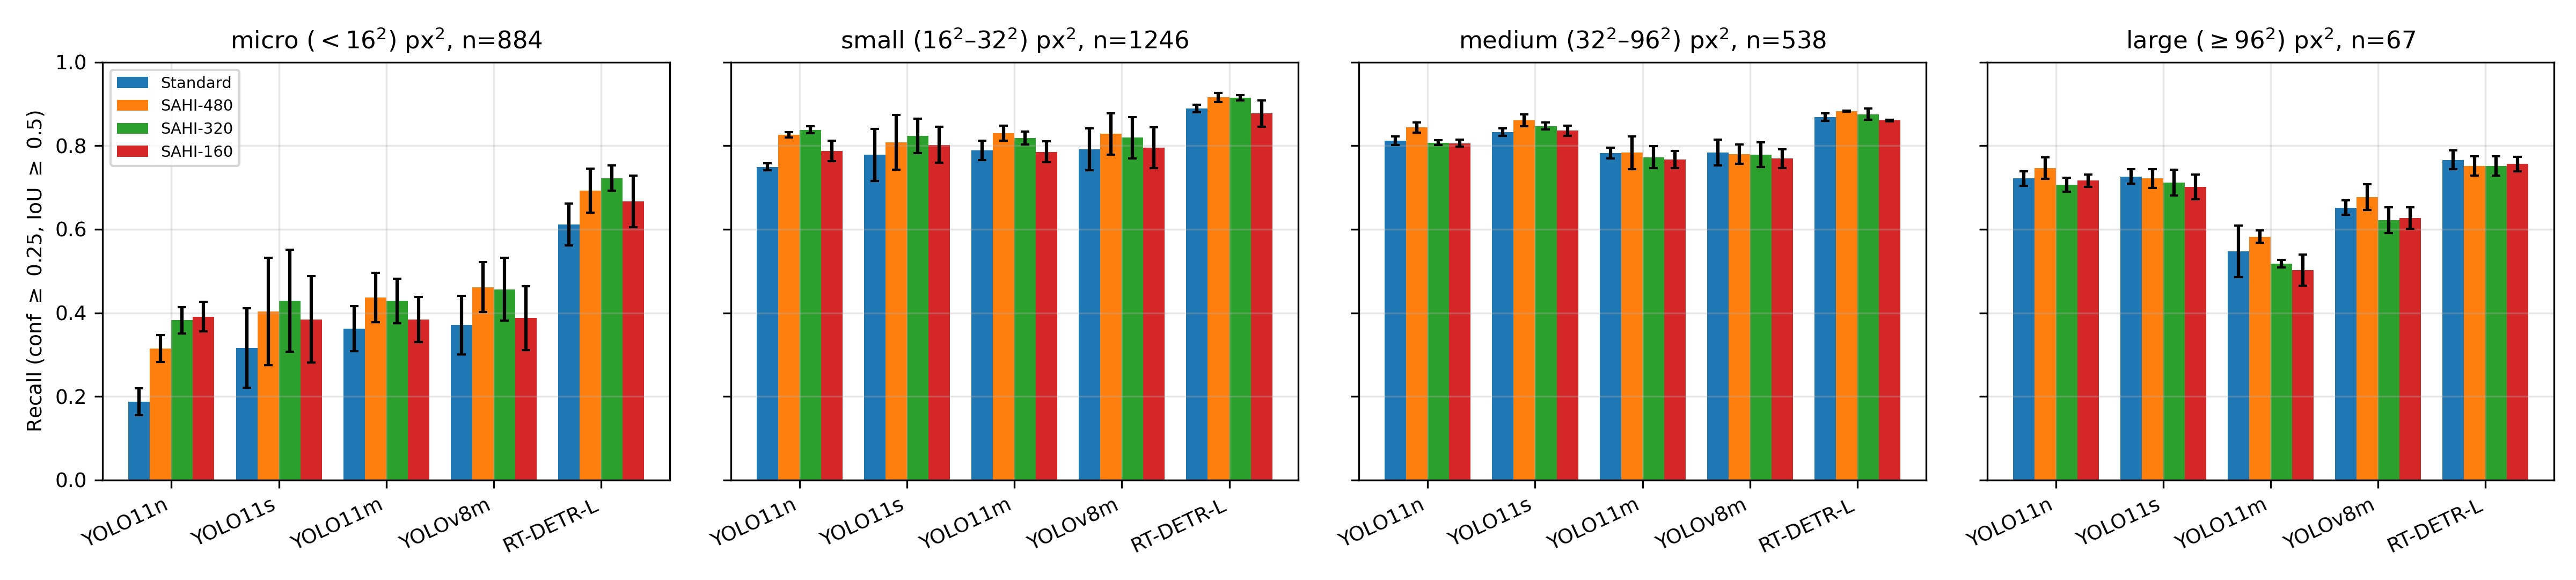

fig_size_recall_sky_grouped.png


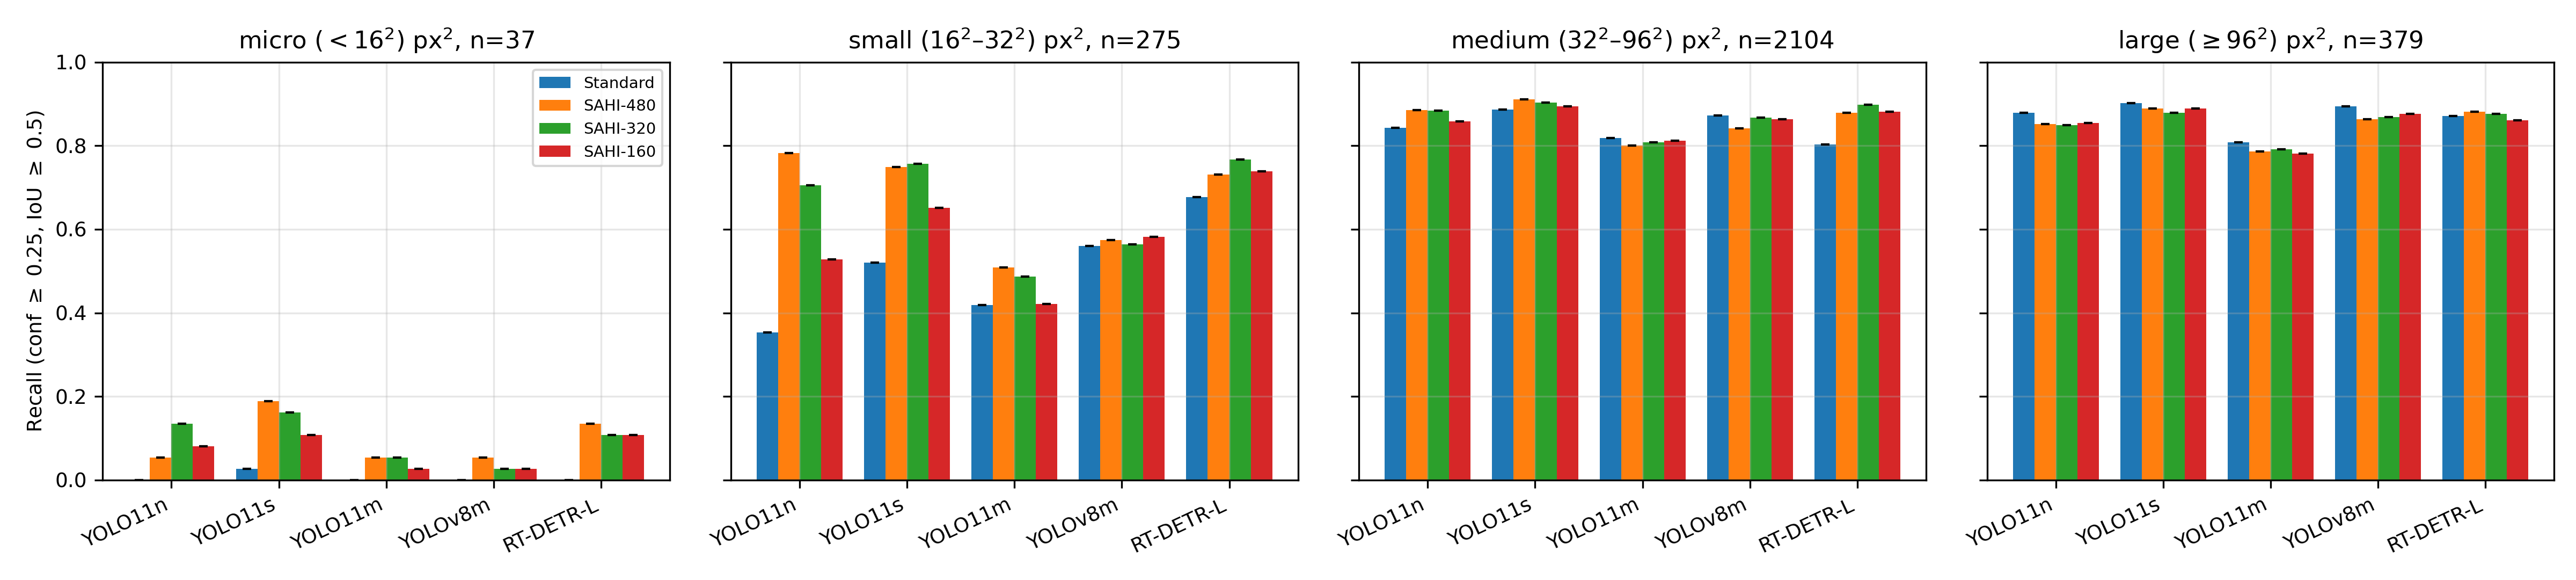

In [6]:
try:
    from IPython.display import Image as _I, display
    for f in sorted(os.listdir(report.PAPER_DIR)):
        if f.endswith(".png"):
            print(f); display(_I(os.path.join(report.PAPER_DIR, f), width=900))
except ImportError:
    print(sorted(os.listdir(report.PAPER_DIR)))